# 03 · Metric and baselines

Writes the competition metric, fixes how a validation score is computed and sets the scores to beat without an image model. Each section ends with key findings.

**Contents**
1. Writing the competition metric (section 1)
2. Choosing the slices and labels to score (section 2)
3. Baselines from the label rates and the slice position (section 3)
4. A LightGBM model on the metadata and the pixel statistics (section 4)
5. Reference points that use the labels (section 5)
6. Measuring how precise the validation is (section 6)
7. Scoring the baselines on the test set (section 7)

Needs:
- `stage_2_train.csv` and `stage_2_sample_submission.csv` in `raw_data_dir` (see `configs/paths.yaml`);
- the slice table `slices.csv` from `scripts/prepare_data.py` (02). No image is read.

In [1]:
import subprocess
import sys
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ich.data.prepare import LABELS, N_FOLDS, SEED, load_labels, read_table
from ich.metrics import bootstrap, image_losses, paired_bootstrap, score, score_by_label
from ich.paths import REPO_ROOT, load_paths
from ich.submission import check_submission, to_submission

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR, PROCESSED = paths["raw_data_dir"], paths["processed_data_dir"]

table = read_table(PROCESSED / "slices.csv")
train = table[table["split"] == "train"].reset_index(drop=True)
test = table[table["split"] == "test"].reset_index(drop=True)
own = load_labels(DATA_DIR / "stage_2_train.csv")  # each image's own labels (02, section 1)

kept = train["keep"].to_numpy()
fold = train["fold"].astype(int).to_numpy()
patient = train["patient"].to_numpy()
y_kept = train[LABELS].astype(float).to_numpy()  # a kept slice: the labels of its position (02, 3.1); a dropped one: its own
y_own = own.loc[train["image"], LABELS].astype(float).to_numpy()
print(f"train slices: {len(train):,} ({kept.sum():,} kept) | patients: {len(set(patient)):,} | test slices: {len(test):,}")

train slices: 752,802 (745,909 kept) | patients: 18,938 | test slices: 121,232


## 1. Writing the competition metric

The score, as described in 00: per image the log loss of the six labels, `any` counted twice, divided by 7, averaged over the images, with the predictions clipped to [1e-15, 1 − 1e-15]. `src/ich/metrics.py` computes it from two arrays with one column per label:
- `score`: the competition score;
- `image_losses`: the loss of every image, whose mean is the score (used for the intervals of section 6);
- `score_by_label`: the loss of each label and its share of the score.

The unit tests in `tests/test_metrics.py` check it on cases whose answer is known:
- a perfect prediction scores 0, a constant 0.5 scores ln 2 = 0.693;
- the loss of each label equals scikit-learn's `log_loss`, and `any` weighs 2/7;
- a division by 6 instead of 7, the bug of two published solutions, would not pass;
- the predictions are clipped at 1e-15;
- the bootstrap resamples whole patients.

In [2]:
tests = subprocess.run([sys.executable, "-m", "pytest", "tests/test_metrics.py", "-q", "--color=no", "-p", "no:cacheprovider"],
                       cwd=REPO_ROOT, capture_output=True, text=True)
print(tests.stdout.strip().splitlines()[-1])

9 passed in 3.87s


How expensive is a confident mistake? The loss of one label for a few predictions:

In [3]:
p = np.array([0.5, 0.1, 0.01, 0.001, 1e-6, 1e-15])
pd.DataFrame({"predicted": [f"{v:g}" for v in p], "loss if the label is 1": -np.log(p), "loss if the label is 0": -np.log(1 - p)}).round(4)

,predicted,loss if the label is 1,loss if the label is 0
0,0.5,0.6931,0.6931
1,0.1,2.3026,0.1054
2,0.01,4.6052,0.0101
3,0.001,6.9078,0.0010
4,1e-06,13.8155,0.0000
5,1e-15,34.5388,0.0000


A bleed predicted at 0.001 costs 6.9 on that label. Missed on `any` and on its subtype, it costs (2 + 1) × 6.9 / 7 = 3.0 for that slice, as much as about 68 slices at the winning score of 0.0438. Predictions near 0 or 1 are only worth it when they are almost never wrong.

### 1.1 Key findings

- **`ich.metrics.score` computes the competition score** and passes its 9 unit tests, among them the check against the division by 6.
- **A confident miss is expensive:** a bleed predicted at 0.001 costs a slice as much as about 68 slices at the winning score.

## 2. Choosing the slices and labels to score

Training uses the kept slices with the labels of their position (02, 3.1). The competition scores every slice with its own label. How many slices differ between the two?

In [4]:
differs = (y_kept != y_own).any(axis=1)
print(f"train slices: {len(train):,} | kept: {kept.sum():,} | dropped: {(~kept).sum():,}")
print(f"kept slices whose position labels differ from their own: {(kept & differs).sum():,} "
      f"({(kept & differs & (y_kept[:, -1] > y_own[:, -1])).sum():,} of them gain `any`)")

train slices: 752,802 | kept: 745,909 | dropped: 6,893
kept slices whose position labels differ from their own: 9 (0 of them gain `any`)


Every baseline is therefore scored both ways:
- **kept:** the kept slices with the labels of their position, as in training;
- **all:** every slice with its own label, as the competition scores. A dropped slice gets the prediction of its own row.

Every prediction is out of fold: the slices of fold *k* are predicted by a model fitted only on kept slices of the other four folds (LightGBM trains on three of them and stops on the fourth), so each score covers all 18,938 patients.

Decisions use **kept**, in this notebook and the next ones: it scores the slices and labels the models learn from. The text quotes kept scores; the tables show **all** beside them.

### 2.1 Key findings

- **Only 9 kept slices have position labels that differ from their own,** and none of them gains `any`. The two targets differ almost only by the 6,893 dropped slices.
- **Every score is out of fold** and covers all 18,938 patients.
- **Decisions use the kept slices** with the labels of their position, the data the models learn from; the all-slices score is shown beside it.

## 3. Baselines from the label rates and the slice position

The first baselines predict a rate for a group of slices: the share of the training slices of that group with each label. A group not seen in training gets the overall rate.

In [5]:
def predict_rates(keys, fit, target, smooth=0):
    # Label rates per group of `keys` over the train slices `fit`, predicted for the rows of `target`;
    # a group not seen gets the overall rate, and `smooth` pulls small groups towards it.
    overall = pd.Series(y_kept[fit].mean(axis=0), index=LABELS)
    if not keys:
        return np.tile(overall.to_numpy(), (len(target), 1))
    groups = pd.DataFrame(y_kept[fit], columns=LABELS).assign(**{k: train.loc[fit, k].to_numpy() for k in keys}).groupby(keys)
    rates = (groups[LABELS].sum() + smooth * overall) / (groups.size().to_numpy()[:, None] + smooth)
    index = pd.MultiIndex.from_frame(target[keys]) if len(keys) > 1 else pd.Index(target[keys[0]])
    return rates.reindex(index).fillna(overall).to_numpy()


def oof_rates(keys, smooth=0):
    # Out of fold: the slices of each fold get the rates of the kept slices of the other folds.
    p = np.zeros_like(y_kept)
    for f in range(N_FOLDS):
        p[fold == f] = predict_rates(keys, kept & (fold != f), train[fold == f], smooth)
    return p


predictions, test_predictions = {}, {}


def evaluate(names):
    return pd.DataFrame({name: {"kept": score(y_kept[kept], predictions[name][kept]), "all": score(y_own, predictions[name])}
                         for name in names}).T.round(5)

### 3.1 One rate per label

The simplest prediction gives every slice the training rate of each label. Its score and where it comes from:

In [6]:
predictions["constant"] = oof_rates([])
display(evaluate(["constant"]))
pd.DataFrame(score_by_label(y_kept[kept], predictions["constant"][kept])).T.round(4)

,kept,all
constant,0.23224,0.23111


,log loss,share of the score
epidural,0.0272,0.0039
intraparenchymal,0.1935,0.0276
intraventricular,0.1520,0.0217
subarachnoid,0.1918,0.0274
subdural,0.2354,0.0336
any,0.4129,0.1180


`any` makes up half of the score; among the subtypes subdural costs the most, epidural almost nothing.

### 3.2 The rate by the place in the scan

Bleeds are rarer near the bottom and the top of a scan (01, 5.3). The rate of each label by the distance to the lowest and to the highest slice of the scan, in 5 mm steps (kept slices):

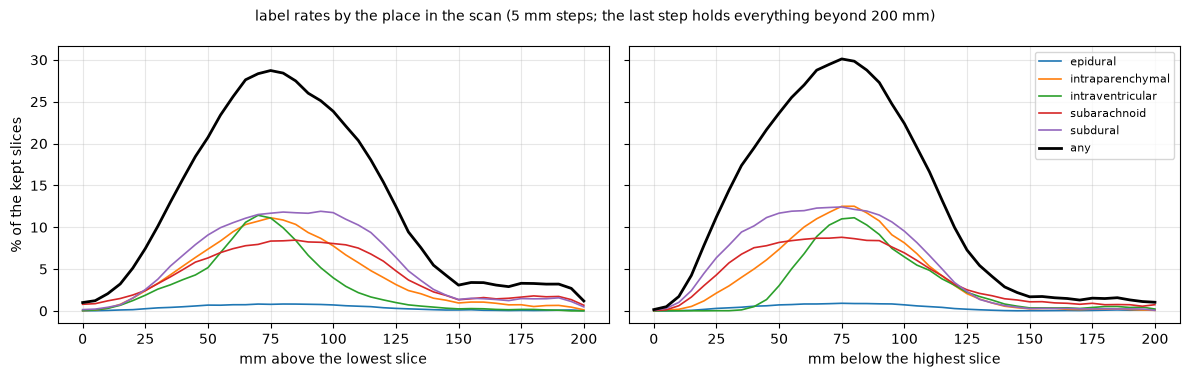

In [7]:
def add_place(frame):
    # The place of each slice in its scan: relative index and distances to the lowest and the highest slice, also in steps.
    by_series = frame.groupby("series")["pos"]
    frame["mm_from_bottom"] = frame["pos"] - by_series.transform("min")
    frame["mm_to_top"] = by_series.transform("max") - frame["pos"]
    frame["rel"] = frame["slice"] / (frame["n_slices"] - 1).clip(lower=1)
    frame["rel_bin"] = (frame["rel"] * 20).clip(upper=19.99).astype(int)
    frame["bottom_bin"] = (frame["mm_from_bottom"] // 5).clip(upper=40).astype(int)
    frame["top_bin"] = (frame["mm_to_top"] // 5).clip(upper=40).astype(int)


add_place(train)
add_place(test)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, xlabel in [(axes[0], "bottom_bin", "mm above the lowest slice"), (axes[1], "top_bin", "mm below the highest slice")]:
    rate = train[kept].groupby(col)[LABELS].mean() * 100
    for label in LABELS:
        ax.plot(rate.index * 5, rate[label], linewidth=2 if label == "any" else 1.2, color="black" if label == "any" else None, label=label)
    ax.set_xlabel(xlabel)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("% of the kept slices")
axes[1].legend(fontsize=8, loc="upper right")
fig.suptitle("label rates by the place in the scan (5 mm steps; the last step holds everything beyond 200 mm)", fontsize=10)
plt.tight_layout()
plt.show()

Bleeds lie in the middle of the scan, most often about 75 mm from either end; near the lowest and the highest slice they are rare.

Four ways to give the place to the rate table: the index of the slice in the scan (20 steps of the relative index), the distance to the lowest slice, the distance to the highest slice, and both distances together (pulled towards the overall rate with a weight of 20 slices, since many pairs are rare):

In [8]:
predictions["index in the scan"] = oof_rates(["rel_bin"])
predictions["mm above the lowest slice"] = oof_rates(["bottom_bin"])
predictions["mm below the highest slice"] = oof_rates(["top_bin"])
predictions["both distances"] = oof_rates(["bottom_bin", "top_bin"], smooth=20)
evaluate(["constant", "index in the scan", "mm above the lowest slice", "mm below the highest slice", "both distances"])

,kept,all
constant,0.23224,0.23111
index in the scan,0.20565,0.20496
mm above the lowest slice,0.21073,0.20991
mm below the highest slice,0.20582,0.20510
both distances,0.20162,0.20091


### 3.3 Key findings

- **One rate per label scores 0.2322**. `any` makes up half of it.
- **Bleeds lie in the middle of the scan:** up to 29–30% of the slices about 75 mm above the lowest and below the highest slice, 1% or less at the edges.
- **The place alone improves the score to 0.2016** with both distances. The distance to the highest slice tells as much as the index in the scan (0.2058 against 0.2057), the distance to the lowest slice less (0.2107).

## 4. A LightGBM model on the metadata and the pixel statistics

Without an image model, the table holds more about a slice than its place: the spacing of the scan, the scanner and simple pixel statistics, computed once from the stored images in 02, 7.3–7.4. The features:

| Group | Features |
|---|---|
| place in the scan | `slice`, `n_slices`, relative index, mm above the lowest and below the highest slice |
| spacing | `local_spacing`, `gap_prev`, `gap_next`, `spacing_change`, `n_stacks`, `interleaved` |
| scanner and site | `writer`, `storage`, `pixel_spacing`, `tilt` |
| pixel statistics | `brain_share`, `head_share`, the height and width of the head box in mm; `brain_share` and `head_share` of the neighbouring positions and their maximum over the scan; `brain_share` relative to that maximum |

Neighbours and maxima are taken over the kept slices, one per position; a dropped slice takes those of its position.

In [9]:
def at_position(frame, values):
    # Values computed on the kept slices of `frame` (one per position), given to every slice at that position.
    scan = frame[frame["keep"]].sort_values(["series", "slice"])
    keyed = pd.concat([scan[["series", "position"]], values(scan)], axis=1)
    return frame[["series", "position"]].merge(keyed, on=["series", "position"], how="left").drop(columns=["series", "position"])


def neighbour_stats(scan):
    columns = {}
    for col in ["brain_share", "head_share"]:
        by_series = scan.groupby("series")[col]
        columns.update({f"{col}_prev": by_series.shift(1), f"{col}_next": by_series.shift(-1), f"{col}_max": by_series.transform("max")})
    return pd.DataFrame(columns)


def make_features(frame):
    X = frame[["slice", "n_slices", "rel", "mm_from_bottom", "mm_to_top", "local_spacing", "gap_prev", "gap_next", "spacing_change",
               "n_stacks", "interleaved", "writer", "storage", "pixel_spacing", "tilt", "brain_share", "head_share"]].copy()
    X["head_height_mm"] = (frame["head_bottom"] - frame["head_top"]) * frame["pixel_spacing"]
    X["head_width_mm"] = (frame["head_right"] - frame["head_left"]) * frame["pixel_spacing"]
    X = X.join(at_position(frame, neighbour_stats))
    X["brain_share_relative"] = X["brain_share"] / X["brain_share_max"]
    for col in ["writer", "storage"]:
        X[col] = pd.Categorical(X[col], categories=sorted(table[col].unique()))
    X[["spacing_change", "interleaved"]] = X[["spacing_change", "interleaved"]].astype(int)
    return X


features, test_features = make_features(train), make_features(test)
SITE = ["writer", "storage", "pixel_spacing", "tilt"]
print(f"{features.shape[1]} features")

26 features


One model per label. Within each fold the model trains on three of the other four folds and stops when the loss on the fourth has not improved for 50 rounds, so the validation fold chooses nothing.

In [10]:
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_data_in_leaf=200, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1)


def lightgbm_oof(X, seed=SEED, X_test=None):
    # Out-of-fold predictions, the gain share of each feature and, if X_test is given, the mean prediction of the 5 fold models.
    p, gain = np.zeros_like(y_kept), pd.Series(0.0, index=X.columns)
    p_test = None if X_test is None else np.zeros((len(X_test), len(LABELS)))
    for f in range(N_FOLDS):
        stop_fold = (f + 1) % N_FOLDS
        fit, stop, val = kept & (fold != f) & (fold != stop_fold), kept & (fold == stop_fold), fold == f
        for j in range(len(LABELS)):
            model = lgb.train({**PARAMS, "seed": seed}, lgb.Dataset(X[fit], y_kept[fit, j]), 2000,
                              valid_sets=[lgb.Dataset(X[stop], y_kept[stop, j])], callbacks=[lgb.early_stopping(50, verbose=False)])
            p[val, j] = model.predict(X[val], num_iteration=model.best_iteration)
            gain += model.feature_importance("gain", iteration=model.best_iteration)
            if X_test is not None:
                p_test[:, j] += model.predict(X_test, num_iteration=model.best_iteration) / N_FOLDS
    return p, gain / gain.sum(), p_test


start = time.time()
predictions["LightGBM"], gain, test_predictions["LightGBM"] = lightgbm_oof(features, X_test=test_features)
print(f"{len(LABELS) * N_FOLDS} models in {time.time() - start:.0f} s")
evaluate(["constant", "both distances", "LightGBM"])

30 models in 58 s


,kept,all
constant,0.23224,0.23111
both distances,0.20162,0.20091
LightGBM,0.16881,0.16822


LightGBM is 0.033 better than the place alone.

Which features does it use? The share of the loss reduction (gain) of each feature, over all 30 models:

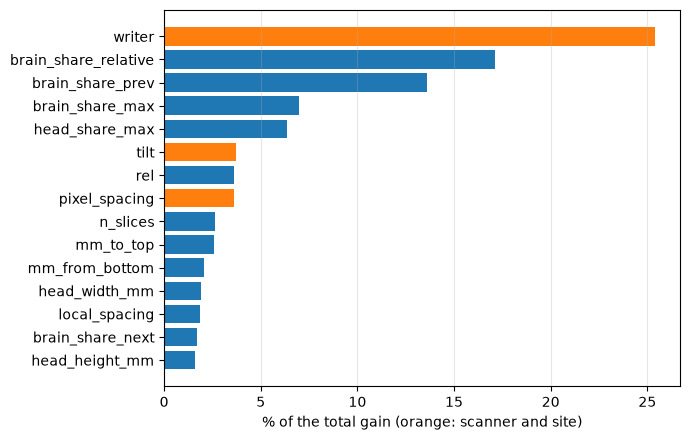

In [11]:
top = gain.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top * 100, color=["tab:orange" if c in SITE else "tab:blue" for c in top.index])
ax.set_xlabel("% of the total gain (orange: scanner and site)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The writer gives the most. Each patient comes from one writer, and the writers stand for sites (02, 2.1). How different are they?

In [12]:
by_writer = train[kept].groupby("writer")[LABELS].mean() * 100
by_writer.insert(0, "% of the test slices", test["writer"].value_counts(normalize=True) * 100)
by_writer.insert(0, "% of the train slices", train[kept]["writer"].value_counts(normalize=True) * 100)
by_writer.round(1)

,% of the train slices,% of the test slices,epidural,intraparenchymal,intraventricular,subarachnoid,subdural,any
writer,,,,,,,,
RSNA Challenge 2019,33.8,37.0,0.2,2.0,1.1,2.4,2.6,6.0
dcm4che-1.4.35,39.1,30.2,0.4,2.4,1.5,2.7,3.5,7.8
dcm4che-1.4.38,27.0,32.8,0.7,11.9,9.5,10.8,15.1,34.6


One writer has almost six times as many slices with a bleed as another (34.6% against 6.0%), and the test set holds all three. If the test labelling shifts the rates of a site (01, 7.1), a model that leans on the site carries the shift with it. How much of the score comes from the scanner and site group?

In [13]:
start = time.time()
predictions["LightGBM without scanner and site"], _, test_predictions["LightGBM without scanner and site"] = lightgbm_oof(
    features.drop(columns=SITE), X_test=test_features.drop(columns=SITE))
print(f"{time.time() - start:.0f} s")
evaluate(["both distances", "LightGBM", "LightGBM without scanner and site"])

54 s


,kept,all
both distances,0.20162,0.20091
LightGBM,0.16881,0.16822
LightGBM without scanner and site,0.18066,0.18002


Without them the score is 0.012 worse: the site is a large part of what the model knows.

One more feature is left out on purpose: the number of scans of the patient. Patients with follow-up scans bleed more often, but is it the same in test?

In [14]:
def scans_per_patient(frame):
    n = frame.groupby("patient")["study"].nunique()
    return n.clip(upper=3).map({1: "1", 2: "2", 3: "3 or more"})


studies = pd.DataFrame({"train patients %": scans_per_patient(train).value_counts(normalize=True) * 100,
                        "test patients %": scans_per_patient(test).value_counts(normalize=True) * 100})
studies["train: % of the kept slices with a bleed"] = train[kept].groupby(train.loc[kept, "patient"].map(scans_per_patient(train)))["any"].mean() * 100
studies.fillna(0).round(1).sort_index()

,train patients %,test patients %,train: % of the kept slices with a bleed
study,,,
1,90.7,100.0,13.9
2,6.6,0.0,14.9
3 or more,2.7,0.0,18.5


Every test patient has one scan, so this feature would not carry over to test.

### 4.1 Key findings

- **LightGBM on 26 metadata and pixel-statistic features scores 0.1688**, 0.033 better than the place alone. The pixel statistics mostly locate the slice in the head: `brain_share` relative to its scan maximum and that of the slice below come right after the writer.
- **The writer gives a quarter of the gain.** One writer (dcm4che-1.4.38) has 34.6% slices with a bleed, the other two 6.0% and 7.8%. Without the scanner and site features the score is 0.1807, 0.012 worse.
- **The site rates may not hold in test:** with the train rate of each writer, the test set would have 15.9% slices with a bleed, the data paper reports 13.1% (01, 7.1). A model that leans on the site can carry this shift into its test predictions.
- **The number of scans per patient cannot be used:** every test patient has one scan, while 9.3% of the train patients have more, and they bleed more often (14.9–18.5% of the slices against 13.9%).

## 5. Reference points that use the labels

Two predictions that use label information a model does not have, to put the scores in scale. They see no image, so they are reference points, not bounds: a model that sees the slice can score better. Both are rates fitted out of fold, as in section 3:
- **the scan's labels known:** for each label, whether the scan has it, together with the index in the scan;
- **the neighbours' labels known:** for each label, its value at the position below and above (or none at the edge of the scan).

The first shows how much of the score is the question *which scan bleeds*, the second how much the labels of neighbouring slices tell about a slice.

In [15]:
for label in LABELS:
    train[f"scan_{label}"] = train.groupby("series")[label].transform("max").astype(int)
neighbours = at_position(train, lambda scan: pd.DataFrame({
    **{f"below_{label}": scan.groupby("series")[label].shift(1) for label in LABELS},
    **{f"above_{label}": scan.groupby("series")[label].shift(-1) for label in LABELS}}))
train = train.join(neighbours.fillna(-1).astype(int))

scan_known, neighbours_known = np.zeros_like(y_kept), np.zeros_like(y_kept)
for j, label in enumerate(LABELS):
    scan_known[:, j] = oof_rates([f"scan_{label}", "rel_bin"])[:, j]
    neighbours_known[:, j] = oof_rates([f"below_{label}", f"above_{label}"])[:, j]
predictions["the scan's labels known"] = scan_known
predictions["the neighbours' labels known"] = neighbours_known
evaluate(["constant", "LightGBM", "the scan's labels known", "the neighbours' labels known"])

,kept,all
constant,0.23224,0.23111
LightGBM,0.16881,0.16822
the scan's labels known,0.10217,0.10232
the neighbours' labels known,0.03249,0.03420


Knowing the scan's labels more than halves the score; knowing the neighbours' labels brings it to 0.032.

All scores so far (kept slices), with the scores of the 1st and the 10th place on Kaggle's final private leaderboard (0.04383 and 0.04712). Those are on the test set, read by three radiologists, so they compare only roughly:

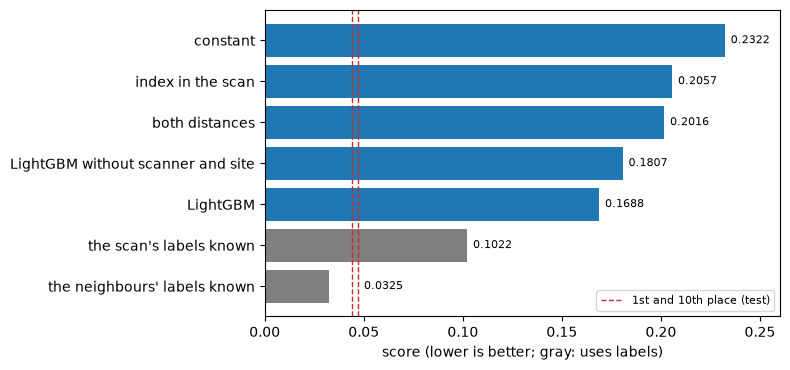

In [16]:
names = ["constant", "index in the scan", "both distances", "LightGBM without scanner and site", "LightGBM",
         "the scan's labels known", "the neighbours' labels known"]
values = [score(y_kept[kept], predictions[name][kept]) for name in names]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], values[::-1], color=["tab:gray" if "known" in n else "tab:blue" for n in names[::-1]])
for i, v in enumerate(values[::-1]):
    ax.text(max(v, 0.04712) + 0.003, i, f"{v:.4f}", va="center", fontsize=8)
for x in [0.04383, 0.04712]:
    ax.axvline(x, color="tab:red", linewidth=1, linestyle="--", label="1st and 10th place (test)" if x == 0.04383 else None)
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("score (lower is better; gray: uses labels)")
ax.set_xlim(0, max(values) * 1.12)
plt.tight_layout()
plt.show()

### 5.1 Key findings

- **Knowing which labels each scan has brings the score from 0.232 to 0.102.** The rest lies in finding the slices within the bleeding scans.
- **Knowing the labels of the neighbouring positions gives 0.0325,** below the 10th place on the test set. The labels change little from one slice to the next, so neighbouring slices tell a model a lot.
- **For this reference point the two targets differ most** (0.0325 kept, 0.0342 all): the own labels of the dropped slices are less predictable from their neighbours, as expected from the label disagreements at close slices (02, 3.1).

## 6. Measuring how precise the validation is

Ranks 3 to 12 of Kaggle's final private leaderboard lie within 0.0022, so the validation has to tell apart differences of a few ten-thousandths. How much do the scores move?

First between folds: the score of each fold on its own (kept slices):

In [17]:
names = ["constant", "both distances", "LightGBM"]
per_fold = pd.DataFrame({name: [score(y_kept[kept & (fold == f)], predictions[name][kept & (fold == f)]) for f in range(N_FOLDS)]
                         for name in names})
per_fold.index.name = "fold"
per_fold.loc["max - min"] = per_fold.max() - per_fold.min()
per_fold.round(4)

,constant,both distances,LightGBM
fold,,,
0,0.2320,0.2020,0.1689
1,0.2282,0.1970,0.1627
2,0.2324,0.2020,0.1706
3,0.2338,0.2029,0.1698
4,0.2347,0.2042,0.1721
max - min,0.0065,0.0072,0.0094


The folds differ by more than the gaps on the leaderboard, and they move together: a fold that is hard for one baseline is hard for all. A single score therefore says little; what matters is the difference between two models on the same slices.

The interval of a score comes from a bootstrap: the slices are drawn again with replacement 2,000 times and the score recomputed, and the middle 95% of the results is the interval. Slices of one scan are alike, so drawing single slices pretends there is far more independent data than there is. Drawing whole patients keeps each patient's slices together. The two ways, for the LightGBM score:

In [18]:
losses = {name: image_losses(y_kept[kept], p[kept]) for name, p in predictions.items()}
intervals = pd.DataFrame({
    "slices drawn": bootstrap(losses["LightGBM"], np.arange(kept.sum())),
    "patients drawn": bootstrap(losses["LightGBM"], patient[kept]),
}).T
intervals["width"] = intervals["high"] - intervals["low"]
intervals.round(5)

,mean,low,high,width
slices drawn,0.16881,0.16804,0.16955,0.00150
patients drawn,0.16881,0.16522,0.17251,0.00728


Two models are compared on the same patients (paired): the bootstrap draws patients and recomputes the difference of the two scores. Is a difference also real if it is small? The pairs of this notebook, and two LightGBM runs that differ only in their random seed (the bagging and the feature sampling):

In [19]:
start = time.time()
predictions["LightGBM, another seed"], _, _ = lightgbm_oof(features, seed=SEED + 1)
losses["LightGBM, another seed"] = image_losses(y_kept[kept], predictions["LightGBM, another seed"][kept])
print(f"{time.time() - start:.0f} s")
pairs = [("constant", "both distances"), ("both distances", "LightGBM"), ("LightGBM without scanner and site", "LightGBM"),
         ("LightGBM", "LightGBM, another seed")]
paired = pd.DataFrame([{"from": a, "to": b, **paired_bootstrap(losses[a], losses[b], patient[kept])} for a, b in pairs])
paired["width"] = paired["high"] - paired["low"]
paired.rename(columns={"mean": "difference"}).round(5)

50 s


,from,to,difference,low,high,width
0,constant,both distances,-0.03062,-0.03147,-0.02972,0.00175
1,both distances,LightGBM,-0.03281,-0.03425,-0.03133,0.00292
2,LightGBM without scanner and site,LightGBM,-0.01185,-0.01275,-0.01090,0.00185
3,LightGBM,"LightGBM, another seed",-0.00003,-0.00014,0.00009,0.00023


### 6.1 Key findings

- **A single score moves a lot:** the folds differ by 0.006–0.009, and the patient-bootstrap interval of the LightGBM score is 0.0073 wide, wider than the gap between the 3rd and the 12th place.
- **Drawing slices instead of patients gives an interval 4.9 times too narrow** (0.0015 against 0.0073).
- **Paired differences are far more precise:** their intervals are 0.0018–0.0029 wide for the steps between the baselines, and two LightGBM runs that differ only in the seed differ by 0.00003 (interval 0.00023 wide).
- So models are compared by the paired patient bootstrap of their difference, not by their single scores.

## 7. Scoring the baselines on the test set

The test labels are not public: Kaggle scores a late submission on the private and the public part of the test set. Four baselines go in, one file each: the constant rates, the rates by both distances, and LightGBM with and without the scanner and site features. For the test set the rates are fitted on all kept train slices, and LightGBM averages its five fold models.

`src/ich/submission.py` writes one row per test slice and label (`ID_<image>_<label>`) and matches them to the IDs of the sample submission, never by row order. `check_submission` stops if an ID is missing, repeated or extra, or a value is missing or outside [0, 1].

In [20]:
test_predictions["constant"] = predict_rates([], kept, test)
test_predictions["both distances"] = predict_rates(["bottom_bin", "top_bin"], kept, test, smooth=20)

SUBMISSIONS = paths["outputs_dir"] / "submissions"
SUBMISSIONS.mkdir(parents=True, exist_ok=True)
sample = pd.read_csv(DATA_DIR / "stage_2_sample_submission.csv")
files = {"constant": "03_constant.csv", "both distances": "03_place.csv", "LightGBM": "03_lightgbm.csv",
         "LightGBM without scanner and site": "03_lightgbm_without_site.csv"}
written = []
for name, file in files.items():
    submission = check_submission(to_submission(test["image"], test_predictions[name]), sample)
    submission.to_csv(SUBMISSIONS / file, index=False, float_format="%.8g")
    written.append({"prediction": name, "file": file, "rows": len(submission), "OOF score (kept)": score(y_kept[kept], predictions[name][kept]),
                    "mean predicted `any` %": test_predictions[name][:, -1].mean() * 100})
print(f"slices with a bleed (all slices, own labels): train {y_own[:, -1].mean() * 100:.1f}% | test, from the data paper: 13.1%")
pd.DataFrame(written).round(4)

slices with a bleed (all slices, own labels): train 14.3% | test, from the data paper: 13.1%


,prediction,file,rows,OOF score (kept),mean predicted `any` %
0,constant,03_constant.csv,727392,0.2322,14.4392
1,both distances,03_place.csv,727392,0.2016,14.5338
2,LightGBM,03_lightgbm.csv,727392,0.1688,15.6385
3,LightGBM without scanner and site,03_lightgbm_without_site.csv,727392,0.1807,15.1632


The scores of the four late submissions (2026-10-16). Kaggle shows the private score of a late submission. The public part holds less than 1% of the test images (Kaggle's leaderboard page), and its scores (0.80–0.95 here) are not used:

In [21]:
private = {"constant": 0.22769, "both distances": 0.19254, "LightGBM": 0.17016, "LightGBM without scanner and site": 0.17658}
leaderboard = pd.DataFrame({"OOF score (kept)": {name: score(y_kept[kept], predictions[name][kept]) for name in private},
                            "private score": private})
leaderboard["private - OOF"] = leaderboard["private score"] - leaderboard["OOF score (kept)"]
leaderboard.round(4)

,OOF score (kept),private score,private - OOF
constant,0.2322,0.2277,-0.0046
both distances,0.2016,0.1925,-0.0091
LightGBM,0.1688,0.1702,0.0013
LightGBM without scanner and site,0.1807,0.1766,-0.0041


The order is the same on the test set. Three of the four score better there than out of fold; only LightGBM with the scanner and site features scores slightly worse. The scanner and site features still help on the test set, but by 0.0064 instead of 0.012.

### 7.1 Key findings

- **Kaggle shows the private score of a late submission,** so the effect of the test set can be measured for each model.
- **The baselines keep their order on the test set:** 0.2277, 0.1925, 0.1766 and 0.1702.
- **The gap between test and validation differs by model:** three of the four score 0.004–0.009 better on the test set, LightGBM with the scanner and site features 0.0013 worse. The test set has fewer bleeding slices than train (13.1% against 14.3%); both LightGBM models predict more (15.2% and 15.6%).
- **The scanner and site features keep about half of their gain** on the test set: 0.0064 instead of 0.012.
- **Test scores are less precise:** the test set holds 3,518 patients, 5.4 times fewer than the validation, so its intervals are about 2.3 times wider than in section 6, roughly 0.017 for a single score and 0.004 for a paired difference. The gaps between test and validation (up to 0.009) are within the noise of a single score; the smaller site gain on the test set (0.0064 against 0.012) is beyond that of a paired difference.

## Summary

- **Metric:** `ich.metrics` computes the competition score (`any` × 2, divided by 7, clipped at 1e-15) and passes its unit tests. A bleed predicted at 0.001 costs a slice as much as about 68 slices at the winning score.
- **Validation:** every score is out of fold over all 18,938 patients. Decisions use the kept slices with the labels of their position; the score on all slices with their own labels differs almost only by the 6,893 dropped slices.
- **Baselines without an image model** (kept slices):

  | Prediction | Score |
  |---|---|
  | one rate per label | 0.2322 |
  | rate by the place in the scan | 0.2016 |
  | LightGBM on metadata and pixel statistics | 0.1688 |
  | the same without the scanner and site features | 0.1807 |
  | reference, uses labels: the scan's labels known | 0.1022 |
  | reference, uses labels: the neighbours' labels known | 0.0325 |

- **The site is a strong signal:** one writer has 34.6% slices with a bleed, the others 6–8%. With these rates the test set would have 15.9% slices with a bleed instead of the reported 13.1%. The number of scans per patient is a train-only signal: every test patient has one scan.
- **Precision:** single scores move by 0.006–0.009 between folds, and the LightGBM score has a 95% interval 0.007 wide. Paired differences on the same patients are far more precise: intervals 0.0018–0.0029 wide between the baselines, and two LightGBM seeds differ by 0.00003 (interval 0.00023 wide).
- **Test set:** the baselines keep their order in late submissions (0.2277 to 0.1702). Three of the four score better on the test set than out of fold; only LightGBM with the site features scores slightly worse. The site features keep about half of their gain (0.0064 instead of 0.012). With 3,518 patients, test scores are about 2.3 times less precise than validation scores.

**Limits**
- The precision figures come from baselines without an image model. Image models have smaller losses and more training randomness, so the seed noise has to be measured again for them.
- All validation scores use the single-reader training labels. The test set was read by three radiologists (00), so a validation score ranks models but does not predict the leaderboard.
- One late submission per baseline. The gaps between test and validation mix the case mix of the test set and its three-reader labels, which these scores cannot tell apart.
- The LightGBM parameters were set once, not tuned; the baselines only set the scores to beat.